# Skrining Prioritas Risiko Diabetes — Puskesmas Harapan Sehat (Jalur C - Kasus C1)

**Tujuan Proyek:** Membangun *pipeline* machine learning terdokumentasi untuk memprioritaskan peserta skrining Posbindu yang membutuhkan pemeriksaan laboratorium lanjutan.

**Kepatuhan Ketentuan Tugas (Jalur C & Kasus C1):**
1. **Pipeline Terdokumentasi:** Memuat dataset UCI Pima Indians Diabetes (768 baris), mengonversi nilai nol tidak masuk akal (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`) menjadi `NaN`, menganalisis pencilan (*outliers*), membagi data secara *stratified* (80:20), serta melakukan imputasi median di dalam `Pipeline` agar bebas *data leakage*.
2. **Perbandingan Model & Dua Skenario Operasional:**
   - **Versi A (Skrining Lengkap - 8 Fitur):** Menggunakan seluruh atribut termasuk `Glucose` dan `Insulin`.
   - **Versi B (Triase Awal Posbindu - 6 Fitur Non-Lab):** Tanpa `Glucose` dan `Insulin` untuk simulasi kondisi lapangan saat hasil tes darah belum tersedia.
   - Model yang diuji: *Logistic Regression* (model sederhana/baseline terkalibrasi), *Random Forest*, dan *Gradient Boosting*.
3. **Evaluasi Komprehensif:** Menampilkan *Confusion Matrix*, Sensitivitas (*Recall*), Spesifisitas, Precision, F1-score, Accuracy, Balanced Accuracy, dan AUC-ROC beserta alasan mengapa akurasi saja tidak memadai pada data tidak seimbang (`65,1%` negatif vs `34,9%` positif).
4. **Nilai Tambah 1 — Analisis Threshold Tuning:** Mengevaluasi pergeseran ambang keputusan (`0.25` – `0.60`) menggunakan probabilitas *Out-Of-Fold* (OOF) pada data latih untuk menekan *False Negative* (pasien berisiko yang terlewat).
5. **Nilai Tambah 2 — Uji Kinerja per Kelompok Usia:** Mengevaluasi keadilan dan konsistensi model pada kelompok usia `21–29`, `30–39`, `40–49`, dan `50+`.
6. **Ekspor Artefak Siap Website (`.joblib`):** Menyimpan model **Versi A** dan **Versi B**, bobot fitur paling berpengaruh, matriks evaluasi, ambang rekomendasi, serta peringatan klinis ke dalam `model_skrining_diabetes.joblib`.


In [9]:
# 1. Import Library & Konfigurasi
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, balanced_accuracy_score, roc_curve
)
from sklearn.base import clone

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.6.1


## 2. Pemuatan Dataset & Audit Nilai Nol / Pencilan

**Sumber & Lisensi Dataset:**
- **Nama:** Pima Indians Diabetes Database (National Institute of Diabetes and Digestive and Kidney Diseases / UCI Machine Learning Repository, 768 baris, 8 fitur prediktor + 1 target `Outcome`).
- **Keputusan Nilai Nol (`0`):** Secara fisiologis, kadar glukosa, tekanan darah diastolik, ketebalan lipatan kulit trisep, insulin serum, dan indeks massa tubuh (BMI) tidak mungkin bernilai `0` pada pasien hidup. Nilai `0` pada kelima kolom tersebut dikonversi menjadi `NaN` agar diimputasi menggunakan median data latih di dalam `Pipeline`. Sementara itu, `Pregnancies = 0` dipertahankan karena valid secara klinis.
- **Keputusan Pencilan (*Outliers*):** Nilai tinggi ekstrem (misalnya `Insulin > 500` atau `Glucose > 190`) merupakan kondisi hiperinsulinemia/hiperglikemia nyata pada subjek berisiko diabetes, sehingga **tidak dihapus** agar model tetap mengenali kasus ekstrem di lapangan.


In [10]:
import io
import os

expected_features = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]
target = "Outcome"
required_cols = expected_features + [target]
col_map_lower = {c.lower(): c for c in required_cols}

def parse_dataset_bytes(raw_bytes):
    text = raw_bytes.decode("utf-8", errors="ignore")
    lines = [ln.strip() for ln in text.splitlines() if ln.strip() and not ln.strip().startswith("%")]

    # Cek jika file berformat ARFF
    upper_lines = [ln.upper() for ln in lines]
    if "@DATA" in upper_lines:
        data_idx = upper_lines.index("@DATA") + 1
        data_text = "\n".join(lines[data_idx:])
        return pd.read_csv(io.StringIO(data_text), header=None, names=required_cols)

    # Cek baris pertama CSV apakah berisi nama kolom (tahan spasi & huruf besar/kecil)
    first_row = pd.read_csv(io.BytesIO(raw_bytes), header=None, nrows=1).iloc[0].astype(str).str.strip().str.lower().tolist()
    if "outcome" in first_row or "pregnancies" in first_row:
        df_tmp = pd.read_csv(io.BytesIO(raw_bytes))
        df_tmp.columns = [col_map_lower.get(str(c).strip().lower(), str(c).strip()) for c in df_tmp.columns]
        return df_tmp[required_cols].copy()

    return pd.read_csv(io.BytesIO(raw_bytes), header=None, names=required_cols)

# Upload dataset melalui Google Colab (dengan fallback otomatis jika dijalankan di lokal)
try:
    from google.colab import files
    print("Silakan pilih dan upload file dataset (pima-indians-diabetes.csv)...")
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Tidak ada file yang diupload.")
    DATA_PATH = next(iter(uploaded.keys()))
    print(f"File berhasil diupload: {DATA_PATH}")
    df_raw = parse_dataset_bytes(uploaded[DATA_PATH])
except ImportError:
    DATA_PATH = "pima-indians-diabetes.csv"
    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError(f"File '{DATA_PATH}' tidak ditemukan di direktori lokal.")
    with open(DATA_PATH, "rb") as f:
        df_raw = parse_dataset_bytes(f.read())

# Konversi seluruh kolom ke numerik & bersihkan baris kosong jika ada
for col in required_cols:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

invalid_target_rows = df_raw[target].isna().sum()
if invalid_target_rows > 0:
    print(f"Info: Menghapus {invalid_target_rows} baris kosong/tidak valid pada kolom Outcome.")
    df_raw = df_raw.dropna(subset=[target]).reset_index(drop=True)

print(f"Dimensi dataset valid: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"Jumlah baris duplikat: {df_raw.duplicated().sum()}")
print("\nDistribusi kelas Outcome:")
class_counts = df_raw[target].value_counts()
class_props = (df_raw[target].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"Jumlah": class_counts, "Persentase (%)": class_props}))

# Audit nilai nol tidak masuk akal & pencilan IQR
zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
audit_rows = []
for col in expected_features:
    n_zero = int((df_raw[col] == 0).sum())
    valid_series = df_raw[col].replace(0, np.nan) if col in zero_invalid_cols else df_raw[col]
    q1, q3 = valid_series.quantile(0.25), valid_series.quantile(0.75)
    iqr = q3 - q1
    n_out = int(((valid_series < (q1 - 1.5 * iqr)) | (valid_series > (q3 + 1.5 * iqr))).sum())
    audit_rows.append({
        "Fitur": col,
        "Nilai 0": n_zero,
        "Persen 0 (%)": round(n_zero / len(df_raw) * 100, 2),
        "Perlakuan 0": "Konversi ke NaN (Missing)" if col in zero_invalid_cols else "Valid (Dipertahankan)",
        "Median Valid": round(float(valid_series.median()), 3),
        "Pencilan IQR": n_out,
        "Keputusan Pencilan": "Dipertahankan (valid secara klinis)"
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# Terapkan konversi 0 -> NaN sebelum split (operasi baris-independen, bebas data leakage)
df = df_raw.copy()
df[zero_invalid_cols] = df[zero_invalid_cols].replace(0, np.nan)
df[target] = df[target].astype(int)

Silakan pilih dan upload file dataset (pima-indians-diabetes.csv)...


Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv
File berhasil diupload: pima-indians-diabetes.csv
Dimensi dataset valid: 768 baris x 9 kolom
Jumlah baris duplikat: 0

Distribusi kelas Outcome:


,Jumlah,Persentase (%)
Outcome,,
0,500,65.1
1,268,34.9


,Fitur,Nilai 0,Persen 0 (%),Perlakuan 0,Median Valid,Pencilan IQR,Keputusan Pencilan
0,Pregnancies,111,14.45,Valid (Dipertahankan),3.000,4,Dipertahankan (valid secara klinis)
1,Glucose,5,0.65,Konversi ke NaN (Missing),117.000,0,Dipertahankan (valid secara klinis)
2,BloodPressure,35,4.56,Konversi ke NaN (Missing),72.000,14,Dipertahankan (valid secara klinis)
3,SkinThickness,227,29.56,Konversi ke NaN (Missing),29.000,3,Dipertahankan (valid secara klinis)
4,Insulin,374,48.70,Konversi ke NaN (Missing),125.000,24,Dipertahankan (valid secara klinis)
5,BMI,11,1.43,Konversi ke NaN (Missing),32.300,8,Dipertahankan (valid secara klinis)
6,DiabetesPedigreeFunction,0,0.00,Valid (Dipertahankan),0.372,29,Dipertahankan (valid secara klinis)
7,Age,0,0.00,Valid (Dipertahankan),29.000,9,Dipertahankan (valid secara klinis)


## 3. Pembagian Data Latih & Uji (*Stratified Split*) serta Pelatihan Model

- Data dibagi menjadi **80% data latih (614 baris)** dan **20% data uji (154 baris)** dengan `stratify=y` agar proporsi kelas positif (`34,9%`) identik pada kedua himpunan.
- `SimpleImputer(strategy="median")` dan `StandardScaler()` ditempatkan di dalam `sklearn.pipeline.Pipeline` sehingga parameter imputasi dan penskalaan hanya dipelajari dari data latih pada setiap lipatan *5-Fold Stratified Cross-Validation*.


In [11]:
features_A = expected_features.copy()
features_B = [c for c in expected_features if c not in ["Glucose", "Insulin"]]

X_train_A, X_test_A, y_train, y_test = train_test_split(
    df[features_A], df[target],
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df[target]
)
X_train_B = X_train_A[features_B].copy()
X_test_B = X_test_A[features_B].copy()

print(f"Data Latih: {len(X_train_A)} baris (Positif: {y_train.sum()} / {y_train.mean()*100:.2f}%)")
print(f"Data Uji  : {len(X_test_A)} baris (Positif: {y_test.sum()} / {y_test.mean()*100:.2f}%)")

def build_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                random_state=RANDOM_STATE, n_jobs=-1
            ))
        ]),
        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
        ])
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

benchmark_rows = []
trained_models = {}
oof_probabilities = {}
test_probabilities = {}

for scenario_key, scenario_label, Xtr, Xte in [
    ("versi_a", "Versi A - Semua fitur (Dengan Lab)", X_train_A, X_test_A),
    ("versi_b", "Versi B - Tanpa Glucose & Insulin (Posbindu)", X_train_B, X_test_B)
]:
    for model_name, pipe in build_models().items():
        cv_auc = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="roc_auc")
        oof_prob = cross_val_predict(pipe, Xtr, y_train, cv=cv, method="predict_proba")[:, 1]

        fitted_pipe = clone(pipe).fit(Xtr, y_train)
        y_pred = fitted_pipe.predict(Xte)
        y_prob = fitted_pipe.predict_proba(Xte)[:, 1]

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
        sens = tp / (tp + fn)
        spec = tn / (tn + fp)

        benchmark_rows.append({
            "Kode Skenario": scenario_key,
            "Skenario": scenario_label,
            "Model": model_name,
            "CV AUC Mean": round(float(cv_auc.mean()), 4),
            "CV AUC Std": round(float(cv_auc.std()), 4),
            "Accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
            "Sensitivity (Recall)": round(float(sens), 4),
            "Specificity": round(float(spec), 4),
            "Precision": round(float(precision_score(y_test, y_pred, zero_division=0)), 4),
            "F1-score": round(float(f1_score(y_test, y_pred, zero_division=0)), 4),
            "AUC-ROC (Test)": round(float(roc_auc_score(y_test, y_prob)), 4),
            "Balanced Accuracy": round(float(balanced_accuracy_score(y_test, y_pred)), 4),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
        })

        trained_models[(scenario_key, model_name)] = fitted_pipe
        oof_probabilities[(scenario_key, model_name)] = oof_prob
        test_probabilities[(scenario_key, model_name)] = y_prob

results_df = pd.DataFrame(benchmark_rows)
display(results_df)


Data Latih: 614 baris (Positif: 214 / 34.85%)
Data Uji  : 154 baris (Positif: 54 / 35.06%)


,Kode Skenario,Skenario,Model,CV AUC Mean,CV AUC Std,Accuracy,Sensitivity (Recall),Specificity,Precision,F1-score,AUC-ROC (Test),Balanced Accuracy,TN,FP,FN,TP
0,versi_a,Versi A - Semua fitur (Dengan Lab),Logistic Regression,0.8444,0.0161,0.7338,0.7037,0.75,0.6032,0.6496,0.8126,0.7269,75,25,16,38
1,versi_a,Versi A - Semua fitur (Dengan Lab),Random Forest,0.8311,0.0224,0.7532,0.6296,0.82,0.6538,0.6415,0.8230,0.7248,82,18,20,34
2,versi_a,Versi A - Semua fitur (Dengan Lab),Gradient Boosting,0.8194,0.0161,0.7597,0.5741,0.86,0.6889,0.6263,0.8315,0.7170,86,14,23,31
3,versi_b,Versi B - Tanpa Glucose & Insulin (Posbindu),Logistic Regression,0.7522,0.0235,0.6818,0.6667,0.69,0.5373,0.5950,0.7289,0.6783,69,31,18,36
4,versi_b,Versi B - Tanpa Glucose & Insulin (Posbindu),Random Forest,0.7147,0.0601,0.6948,0.5556,0.77,0.5660,0.5607,0.7506,0.6628,77,23,24,30
5,versi_b,Versi B - Tanpa Glucose & Insulin (Posbindu),Gradient Boosting,0.7059,0.0843,0.7143,0.5556,0.80,0.6000,0.5769,0.7698,0.6778,80,20,24,30


### Mengapa Akurasi Saja Tidak Cukup?

Pada dataset ini, kelas tidak seimbang (`65,10%` negatif vs `34,90%` positif):
- **Baseline Mayoritas (Dummy Negatif):** Jika sebuah model menebak seluruh peserta sebagai **Negatif (`0`)**, model tersebut tetap memperoleh **Akurasi 65,10%**, padahal **Sensitivitasnya 0,00%** (100% pasien diabetes gagal terdeteksi).
- **Konteks Klinis Puskesmas:** Dalam triase awal Posbindu, kesalahan **False Negative (FN)**—yakni peserta yang sebenarnya berisiko tinggi diabetes tetapi diprediksi negatif sehingga tidak dirujuk ke laboratorium—jauh lebih berbahaya daripada **False Positive (FP)** yang hanya berujung pada pemeriksaan gula darah lanjutan. Oleh karena itu, **Sensitivitas (Recall)** dan **AUC-ROC** menjadi metrik utama pendamping akurasi.


## 4. Analisis Threshold Tuning (Nilai Tambah)

Secara default, klasifikasi biner menggunakan ambang probabilitas `0.50`. Untuk kebutuhan skrining Posbindu, kita mengevaluasi variasi ambang dari `0.25` hingga `0.60`:
- Pemilihan ambang operasional didasarkan pada probabilitas **Out-Of-Fold (OOF)** data latih agar tidak mengintip data uji (*no test-set leakage*).
- Selanjutnya, dampak ambang terpilih diverifikasi pada **data uji (`X_test`)** untuk melihat peningkatan **Sensitivitas** dan penurunan kasus terlewat (**False Negative**).


Model terpilih [versi_a]: Logistic Regression (CV AUC = 0.8444)
Model terpilih [versi_b]: Logistic Regression (CV AUC = 0.7522)

=== Tabel Threshold Tuning: VERSI_A (Logistic Regression) ===


,Threshold,OOF_Sensitivity,OOF_Specificity,OOF_Accuracy,Test_Sensitivity,Test_Specificity,Test_Precision,Test_F1,Test_Accuracy,Test_TN,Test_FP,Test_FN,Test_TP
0,0.25,0.9252,0.4900,0.6417,0.9259,0.56,0.5319,0.6757,0.6883,56,44,4,50
1,0.30,0.9019,0.5350,0.6629,0.8889,0.60,0.5455,0.6761,0.7013,60,40,6,48
2,0.35,0.8645,0.6250,0.7085,0.8889,0.64,0.5714,0.6957,0.7273,64,36,6,48
3,0.40,0.8084,0.6700,0.7182,0.8333,0.66,0.5696,0.6767,0.7208,66,34,9,45
4,0.45,0.7804,0.7225,0.7427,0.7778,0.71,0.5915,0.6720,0.7338,71,29,12,42
5,0.50,0.7009,0.7950,0.7622,0.7037,0.75,0.6032,0.6496,0.7338,75,25,16,38
6,0.55,0.6869,0.8325,0.7818,0.6296,0.78,0.6071,0.6182,0.7273,78,22,20,34
7,0.60,0.6402,0.8675,0.7883,0.5741,0.79,0.5962,0.5849,0.7143,79,21,23,31



=== Tabel Threshold Tuning: VERSI_B (Logistic Regression) ===


,Threshold,OOF_Sensitivity,OOF_Specificity,OOF_Accuracy,Test_Sensitivity,Test_Specificity,Test_Precision,Test_F1,Test_Accuracy,Test_TN,Test_FP,Test_FN,Test_TP
0,0.25,0.9626,0.3000,0.5309,0.9815,0.34,0.4454,0.6127,0.5649,34,66,1,53
1,0.30,0.9393,0.3975,0.5863,0.9259,0.40,0.4545,0.6098,0.5844,40,60,4,50
2,0.35,0.8738,0.4575,0.6026,0.8889,0.48,0.4800,0.6234,0.6234,48,52,6,48
3,0.40,0.8458,0.5500,0.6531,0.7778,0.54,0.4773,0.5915,0.6234,54,46,12,42
4,0.45,0.7570,0.6200,0.6678,0.7222,0.60,0.4937,0.5865,0.6429,60,40,15,39
5,0.50,0.6729,0.6775,0.6759,0.6667,0.69,0.5373,0.5950,0.6818,69,31,18,36
6,0.55,0.5607,0.7275,0.6694,0.5926,0.75,0.5614,0.5766,0.6948,75,25,22,32
7,0.60,0.4860,0.7875,0.6824,0.4444,0.77,0.5106,0.4752,0.6558,77,23,30,24


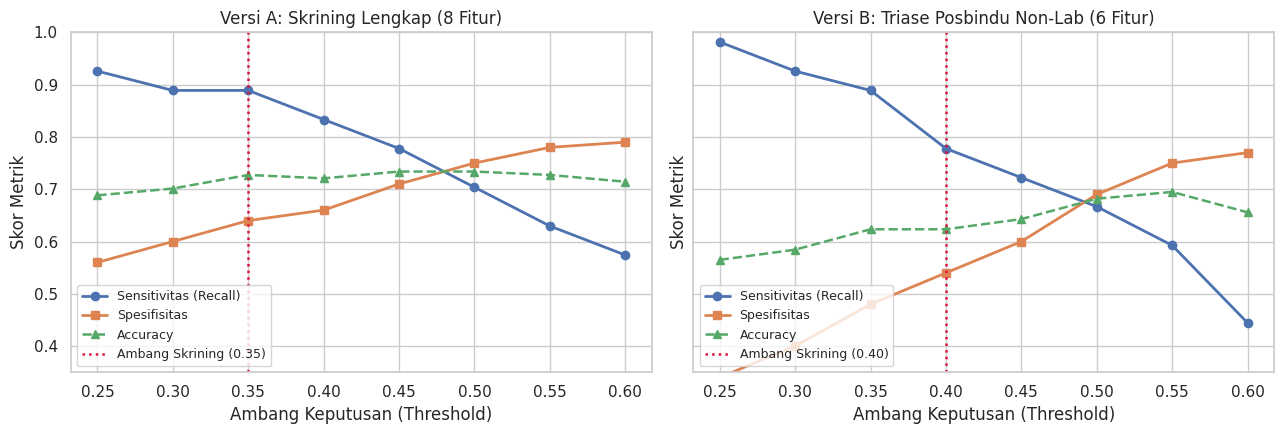

In [12]:
# Pilih model terbaik per skenario berdasarkan CV AUC Mean pada data latih
selected_models_info = {}
for scenario_key, feats in [("versi_a", features_A), ("versi_b", features_B)]:
    sub = results_df[results_df["Kode Skenario"] == scenario_key].sort_values("CV AUC Mean", ascending=False)
    best_row = sub.iloc[0]
    selected_models_info[scenario_key] = {
        "model_name": best_row["Model"],
        "features": feats,
        "cv_auc": float(best_row["CV AUC Mean"])
    }
    print(f"Model terpilih [{scenario_key}]: {best_row['Model']} (CV AUC = {best_row['CV AUC Mean']:.4f})")

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_tables = {}

for scenario_key, info in selected_models_info.items():
    mname = info["model_name"]
    oof_p = oof_probabilities[(scenario_key, mname)]
    te_p = test_probabilities[(scenario_key, mname)]

    t_rows = []
    for th in thresholds:
        # Evaluasi OOF (Data Latih)
        pred_oof = (oof_p >= th).astype(int)
        tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_train, pred_oof, labels=[0, 1]).ravel()

        # Evaluasi Data Uji
        pred_te = (te_p >= th).astype(int)
        tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_te, labels=[0, 1]).ravel()

        t_rows.append({
            "Threshold": th,
            "OOF_Sensitivity": round(float(tp_o / (tp_o + fn_o)), 4),
            "OOF_Specificity": round(float(tn_o / (tn_o + fp_o)), 4),
            "OOF_Accuracy": round(float((tp_o + tn_o) / len(y_train)), 4),
            "Test_Sensitivity": round(float(tp_t / (tp_t + fn_t)), 4),
            "Test_Specificity": round(float(tn_t / (tn_t + fp_t)), 4),
            "Test_Precision": round(float(tp_t / max(1, tp_t + fp_t)), 4),
            "Test_F1": round(float(f1_score(y_test, pred_te, zero_division=0)), 4),
            "Test_Accuracy": round(float((tp_t + tn_t) / len(y_test)), 4),
            "Test_TN": int(tn_t), "Test_FP": int(fp_t), "Test_FN": int(fn_t), "Test_TP": int(tp_t)
        })
    t_df = pd.DataFrame(t_rows)
    threshold_tables[scenario_key] = t_df
    print(f"\n=== Tabel Threshold Tuning: {scenario_key.upper()} ({mname}) ===")
    display(t_df)

# Visualisasi Trade-off Sensitivitas vs Spesifisitas pada perubahan Threshold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (scenario_key, title) in zip(axes, [
    ("versi_a", "Versi A: Skrining Lengkap (8 Fitur)"),
    ("versi_b", "Versi B: Triase Posbindu Non-Lab (6 Fitur)")
]):
    t_df = threshold_tables[scenario_key]
    ax.plot(t_df["Threshold"], t_df["Test_Sensitivity"], marker="o", linewidth=2, label="Sensitivitas (Recall)")
    ax.plot(t_df["Threshold"], t_df["Test_Specificity"], marker="s", linewidth=2, label="Spesifisitas")
    ax.plot(t_df["Threshold"], t_df["Test_Accuracy"], marker="^", linestyle="--", linewidth=1.8, label="Accuracy")
    rec_th = 0.35 if scenario_key == "versi_a" else 0.40
    ax.axvline(rec_th, color="crimson", linestyle=":", linewidth=1.8, label=f"Ambang Skrining ({rec_th:.2f})")
    ax.set_title(title)
    ax.set_xlabel("Ambang Keputusan (Threshold)")
    ax.set_ylabel("Skor Metrik")
    ax.set_ylim(0.35, 1.0)
    ax.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()


## 5. Interpretabilitas Faktor Paling Berpengaruh & Uji Kinerja per Kelompok Usia (Nilai Tambah)

1. **Faktor Paling Berpengaruh:** Mengekstrak bobot koefisien terstandardisasi (`|coef_|`) pada *Logistic Regression* (atau `feature_importances_` pada model berbasis pohon) untuk ditampilkan langsung di antarmuka website.
2. **Uji Kinerja per Kelompok Usia:** Mengevaluasi model pada empat kelompok usia (`21–29`, `30–39`, `40–49`, dan `50+`) menggunakan ambang skrining rekomendasi (`0.35` untuk Versi A, `0.40` untuk Versi B) sekaligus mencatat ukuran sampel tiap kelompok.


In [14]:
def extract_feature_importance(fitted_pipe, feature_names):
    estimator = fitted_pipe.named_steps["model"]
    if hasattr(estimator, "coef_"):
        raw_weights = estimator.coef_[0]
        abs_weights = np.abs(raw_weights)
        norm_weights = abs_weights / abs_weights.sum()
        items = []
        for feat, coef_val, imp_val in zip(feature_names, raw_weights, norm_weights):
            items.append({
                "feature": feat,
                "importance": round(float(imp_val), 4),
                "coefficient": round(float(coef_val), 4),
                "direction": "Meningkatkan Risiko (+)" if coef_val >= 0 else "Menurunkan Risiko (-)"
            })
    elif hasattr(estimator, "feature_importances_"):
        imps = estimator.feature_importances_
        items = [
            {
                "feature": feat,
                "importance": round(float(imp_val), 4),
                "coefficient": None,
                "direction": "Non-linear (Tree)"
            }
            for feat, imp_val in zip(feature_names, imps)
        ]
    else:
        items = [{"feature": feat, "importance": 0.0, "coefficient": None, "direction": "-"} for feat in feature_names]
    return sorted(items, key=lambda x: x["importance"], reverse=True)

feature_importances_map = {}
for scenario_key, info in selected_models_info.items():
    pipe = trained_models[(scenario_key, info["model_name"])]
    fi_list = extract_feature_importance(pipe, info["features"])
    feature_importances_map[scenario_key] = fi_list
    print(f"=== Peringkat Faktor Berpengaruh: {scenario_key.upper()} ===")
    display(pd.DataFrame(fi_list))

# Uji kinerja per kelompok usia pada Data Uji
age_bins = [20, 29, 39, 49, 120]
age_labels = ["21-29", "30-39", "40-49", "50+"]
age_groups_test = pd.cut(X_test_A["Age"], bins=age_bins, labels=age_labels)

recommended_thresholds = {"versi_a": 0.35, "versi_b": 0.40}
age_eval_map = {}

for scenario_key, info in selected_models_info.items():
    th = recommended_thresholds[scenario_key]
    probs = test_probabilities[(scenario_key, info["model_name"])]
    preds = (probs >= th).astype(int)

    age_rows = []
    for grp in age_labels:
        mask = (age_groups_test == grp).values
        n_grp = int(mask.sum())
        yt_g = y_test.values[mask]
        yp_g = preds[mask]
        yprob_g = probs[mask]

        tn_g, fp_g, fn_g, tp_g = confusion_matrix(yt_g, yp_g, labels=[0, 1]).ravel()
        sens_g = round(float(tp_g / (tp_g + fn_g)), 4) if (tp_g + fn_g) > 0 else None
        spec_g = round(float(tn_g / (tn_g + fp_g)), 4) if (tn_g + fp_g) > 0 else None
        auc_g = round(float(roc_auc_score(yt_g, yprob_g)), 4) if len(np.unique(yt_g)) > 1 else None

        age_rows.append({
            "Kelompok Usia": grp,
            "Jumlah Sampel (n)": n_grp,
            "Positif Aktual": int(yt_g.sum()),
            "Threshold": th,
            "Accuracy": round(float(accuracy_score(yt_g, yp_g)), 4),
            "Sensitivity": sens_g,
            "Specificity": spec_g,
            "AUC-ROC": auc_g,
            "Catatan": "Sampel kecil (<20), interpretasi hati-hati" if n_grp < 20 else "Memadai"
        })
    age_df = pd.DataFrame(age_rows)
    age_eval_map[scenario_key] = age_df
    print(f"=== Evaluasi per Kelompok Usia: {scenario_key.upper()} (Threshold = {th}) ===")
    display(age_df)


=== Peringkat Faktor Berpengaruh: VERSI_A ===


,feature,importance,coefficient,direction
0,Glucose,0.4207,1.1835,Meningkatkan Risiko (+)
1,BMI,0.2522,0.7096,Meningkatkan Risiko (+)
2,Pregnancies,0.1325,0.3729,Meningkatkan Risiko (+)
3,DiabetesPedigreeFunction,0.1023,0.2877,Meningkatkan Risiko (+)
4,Age,0.0663,0.1864,Meningkatkan Risiko (+)
5,Insulin,0.0159,-0.0446,Menurunkan Risiko (-)
6,BloodPressure,0.0052,-0.0146,Menurunkan Risiko (-)
7,SkinThickness,0.0050,0.0140,Meningkatkan Risiko (+)


=== Peringkat Faktor Berpengaruh: VERSI_B ===


,feature,importance,coefficient,direction
0,BMI,0.3796,0.7225,Meningkatkan Risiko (+)
1,Age,0.2153,0.4099,Meningkatkan Risiko (+)
2,DiabetesPedigreeFunction,0.1556,0.2962,Meningkatkan Risiko (+)
3,Pregnancies,0.1525,0.2902,Meningkatkan Risiko (+)
4,SkinThickness,0.0572,0.1089,Meningkatkan Risiko (+)
5,BloodPressure,0.0397,0.0756,Meningkatkan Risiko (+)


=== Evaluasi per Kelompok Usia: VERSI_A (Threshold = 0.35) ===


,Kelompok Usia,Jumlah Sampel (n),Positif Aktual,Threshold,Accuracy,Sensitivity,Specificity,AUC-ROC,Catatan
0,21-29,85,16,0.35,0.7176,0.6875,0.7246,0.7654,Memadai
1,30-39,30,20,0.35,0.8333,0.9500,0.6000,0.8450,Memadai
2,40-49,24,12,0.35,0.7083,1.0000,0.4167,0.8611,Memadai
3,50+,15,6,0.35,0.6000,1.0000,0.3333,0.6481,"Sampel kecil (<20), interpretasi hati-hati"


=== Evaluasi per Kelompok Usia: VERSI_B (Threshold = 0.4) ===


,Kelompok Usia,Jumlah Sampel (n),Positif Aktual,Threshold,Accuracy,Sensitivity,Specificity,AUC-ROC,Catatan
0,21-29,85,16,0.4,0.6000,0.4375,0.6377,0.6929,Memadai
1,30-39,30,20,0.4,0.8000,0.9000,0.6000,0.8600,Memadai
2,40-49,24,12,0.4,0.5417,0.9167,0.1667,0.5764,Memadai
3,50+,15,6,0.4,0.5333,1.0000,0.2222,0.5556,"Sampel kecil (<20), interpretasi hati-hati"


## 6. Ekspor Artefak Model Lengkap ke `.joblib` untuk Integrasi Website

File `model_skrining_diabetes.joblib` menyimpan seluruh komponen yang dibutuhkan oleh aplikasi web (Laravel/Python/FastAPI/Flask/Streamlit) dalam satu objek terstruktur:
- `models["versi_a"]`: Pipeline terlatih 8 fitur (dengan lab), ambang rekomendasi `0.35`, tabel threshold tuning, metrik evaluasi lengkap, faktor paling berpengaruh, serta evaluasi kelompok usia.
- `models["versi_b"]`: Pipeline terlatih 6 fitur (non-lab Posbindu), ambang rekomendasi `0.40`, tabel threshold tuning, metrik evaluasi lengkap, faktor paling berpengaruh, serta evaluasi kelompok usia.
- `all_benchmarks`: Tabel perbandingan seluruh model (*Logistic Regression*, *Random Forest*, *Gradient Boosting*) untuk ditampilkan pada halaman transparansi evaluasi di website.
- `disclaimer`: Teks peringatan klinis wajib.


In [15]:
def get_metrics_at_threshold(y_true, y_prob, th):
    y_pred = (y_prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(th),
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "sensitivity": round(float(tp / (tp + fn)), 4),
        "specificity": round(float(tn / (tn + fp)), 4),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "f1_score": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(y_true, y_prob)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_true, y_pred)), 4),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}
    }

artifact = {
    "project_title": "Sistem Prioritas Skrining Risiko Diabetes - Puskesmas Harapan Sehat",
    "sklearn_version": sklearn.__version__,
    "disclaimer": (
        "PERINGATAN KLINIS: Hasil prediksi ini merupakan alat bantu skrining awal untuk "
        "memprioritaskan pemeriksaan laboratorium lanjutan (prototipe penelitian), BUKAN diagnosis medis, "
        "dan tidak boleh digunakan secara langsung untuk keputusan klinis tanpa pemeriksaan dokter/tenaga kesehatan."
    ),
    "dataset_summary": {
        "source": "UCI / NIDDK Pima Indians Diabetes Database (768 baris, 8 fitur prediktor)",
        "total_samples": int(len(df)),
        "train_samples": int(len(X_train_A)),
        "test_samples": int(len(X_test_A)),
        "class_distribution": {"negative_0": int((df[target] == 0).sum()), "positive_1": int((df[target] == 1).sum())},
        "zero_handling": "Nilai 0 pada Glucose, BloodPressure, SkinThickness, Insulin, dan BMI dikonversi menjadi NaN lalu diimputasi median data latih di dalam Pipeline.",
        "outlier_handling": "Pencilan medis ekstrem dipertahankan karena merepresentasikan variasi klinis nyata.",
        "limitation": "Dataset berasal dari populasi perempuan keturunan Pima usia >= 21 tahun sehingga memerlukan kalibrasi ulang sebelum diterapkan pada populasi pasien Indonesia."
    },
    "models": {},
    "all_benchmarks": results_df.to_dict(orient="records")
}

scenario_titles = {
    "versi_a": "Versi A - Skrining Lengkap (Dengan Hasil Lab Glucose & Insulin)",
    "versi_b": "Versi B - Triase Awal Posbindu (Non-Lab Tanpa Glucose & Insulin)"
}

for scenario_key, info in selected_models_info.items():
    mname = info["model_name"]
    pipe = trained_models[(scenario_key, mname)]
    te_prob = test_probabilities[(scenario_key, mname)]
    rec_th = recommended_thresholds[scenario_key]

    # Hitung median data latih sebagai informasi referensi input kosong di UI
    Xtr_ref = X_train_A if scenario_key == "versi_a" else X_train_B
    train_medians = {col: round(float(Xtr_ref[col].median()), 3) for col in info["features"]}

    artifact["models"][scenario_key] = {
        "title": scenario_titles[scenario_key],
        "model_name": mname,
        "pipeline": pipe,
        "features": info["features"],
        "train_medians": train_medians,
        "default_threshold": rec_th,
        "metrics_default_050": get_metrics_at_threshold(y_test.values, te_prob, 0.50),
        "metrics_recommended": get_metrics_at_threshold(y_test.values, te_prob, rec_th),
        "threshold_tuning": threshold_tables[scenario_key].to_dict(orient="records"),
        "feature_importances": feature_importances_map[scenario_key],
        "age_group_evaluation": age_eval_map[scenario_key].to_dict(orient="records")
    }

OUTPUT_JOBLIB = "model_skrining_diabetes.joblib"
joblib.dump(artifact, OUTPUT_JOBLIB)
print(f"Artefak berhasil diekspor ke: {OUTPUT_JOBLIB}")

# Verifikasi pemuatan ulang & simulasi inferensi untuk Versi A dan Versi B
loaded = joblib.load(OUTPUT_JOBLIB)
sample_patient = {
    "Pregnancies": 4,
    "Glucose": 148,
    "BloodPressure": 76,
    "SkinThickness": 30,
    "Insulin": 0,   # Simulasi input 0 / belum ada lab -> otomatis diubah jadi NaN
    "BMI": 33.6,
    "DiabetesPedigreeFunction": 0.627,
    "Age": 45
}

for mode in ["versi_a", "versi_b"]:
    m_info = loaded["models"][mode]
    feats = m_info["features"]
    th = m_info["default_threshold"]
    row_dict = {}
    for f in feats:
        val = sample_patient.get(f, np.nan)
        if f in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] and val == 0:
            val = np.nan
        row_dict[f] = val
    X_input = pd.DataFrame([row_dict])[feats]
    prob = float(m_info["pipeline"].predict_proba(X_input)[0, 1])
    pred = int(prob >= th)
    print(f"Simulasi [{mode}] -> Probabilitas: {prob:.4f} | Threshold: {th:.2f} | Prioritas Rujukan: {bool(pred)}")


Artefak berhasil diekspor ke: model_skrining_diabetes.joblib
Simulasi [versi_a] -> Probabilitas: 0.7757 | Threshold: 0.35 | Prioritas Rujukan: True
Simulasi [versi_b] -> Probabilitas: 0.6381 | Threshold: 0.40 | Prioritas Rujukan: True
